## EDA

In [1]:
# Import the libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load combined file made in Notebook 01
df = pd.read_csv("../data/processed/all_indices_clean.csv")
df["Date"] = pd.to_datetime(df["Date"])

df.info()
print(df.head())
print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 5904 entries, 0 to 5903
Data columns (total 21 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Date          5904 non-null   datetime64[us]
 1   High_(t-1)    5904 non-null   float64       
 2   Low_(t-1)     5904 non-null   float64       
 3   Close_(t-1)   5904 non-null   float64       
 4   Open_(t-1)    5904 non-null   float64       
 5   Volume_(t-1)  5904 non-null   int64         
 6   SMA_6         5904 non-null   float64       
 7   EMA_26        5904 non-null   float64       
 8   EMA_12        5904 non-null   float64       
 9   MACD          5904 non-null   float64       
 10  MACD_Signal   5904 non-null   float64       
 11  RSI_6         5904 non-null   float64       
 12  RSV_9         5904 non-null   float64       
 13  PSY_13        5904 non-null   float64       
 14  K_9           5904 non-null   float64       
 15  D_3           5904 non-null   float64       
 16 

### Objective 1: The Trend (Raw prices)

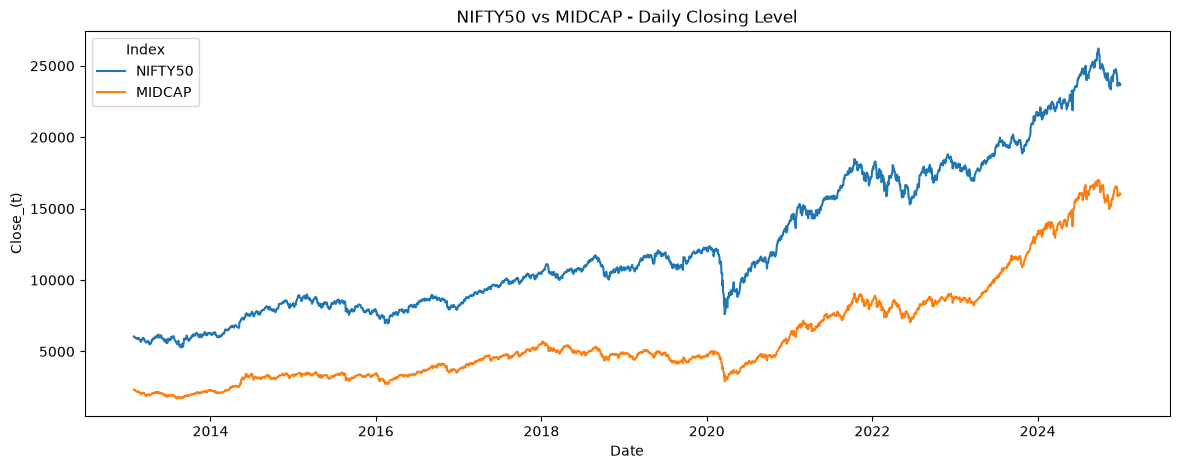

In [2]:
# Objective 1 - how did both indices move from 2013 to 2024?
plt.figure(figsize=(14, 5))
sns.lineplot(data=df, x="Date", y="Close_(t)", hue="Index")
plt.title("NIFTY50 vs MIDCAP - Daily Closing Level")
plt.show()

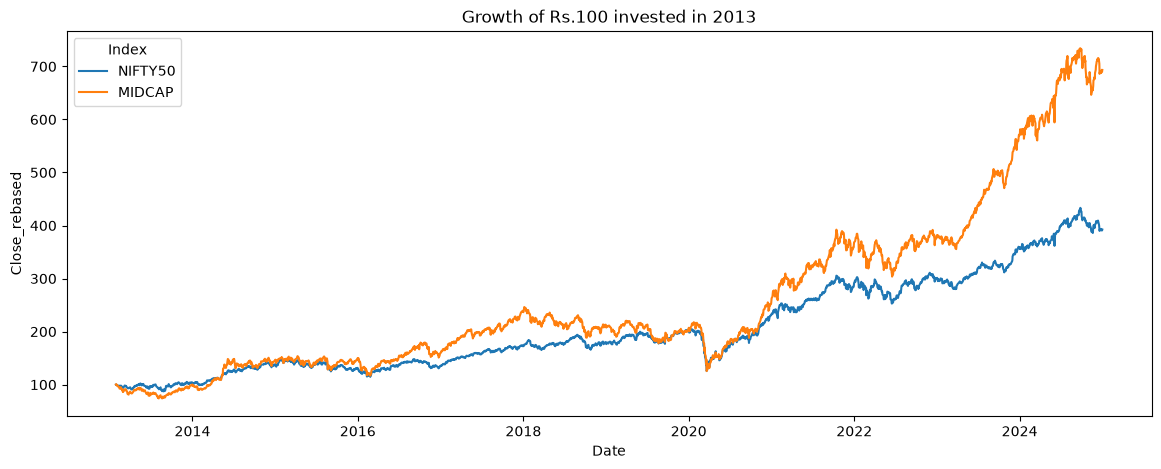

Total growth 2013-2024 (%):
 Index
MIDCAP     593.4
NIFTY50    292.5
Name: Close_rebased, dtype: float64


In [3]:
# Pretend we invested Rs.100 in each index at the start - now lines show % growth directly
df["Close_rebased"] = df.groupby("Index")["Close_(t)"].transform(lambda x: x / x.iloc[0] * 100)

plt.figure(figsize=(14, 5))
sns.lineplot(data=df, x="Date", y="Close_rebased", hue="Index")
plt.title("Growth of Rs.100 invested in 2013")
plt.show()

growth = df.groupby("Index")["Close_rebased"].last() - 100
print("Total growth 2013-2024 (%):\n", growth.round(1))

### Objective 2: Daily Returns

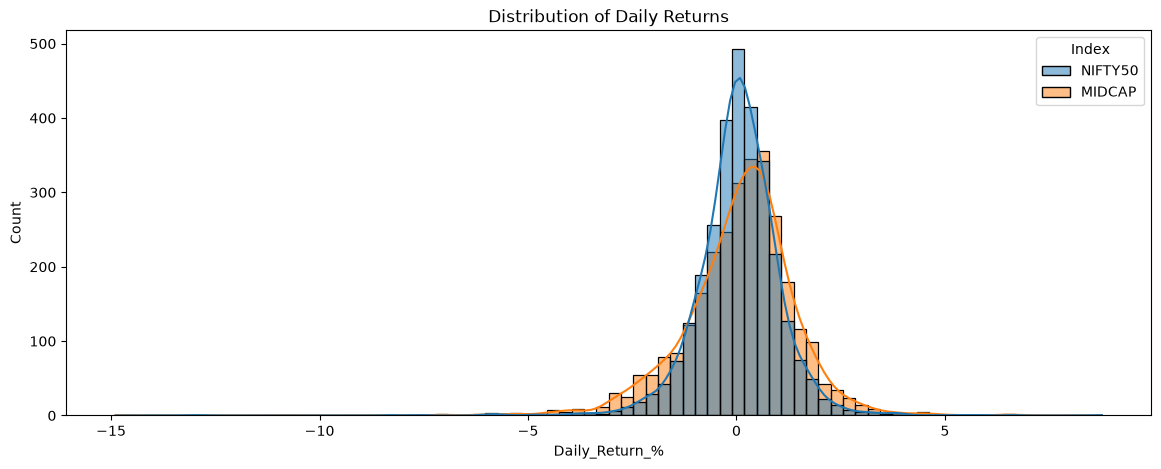

In [4]:
# Objective 2 - daily % change of each index
df["Daily_Return_%"] = df.groupby("Index")["Close_(t)"].pct_change(fill_method=None) * 100

plt.figure(figsize=(14, 5))
sns.histplot(data=df, x="Daily_Return_%", hue="Index", kde=True, bins=80)
plt.title("Distribution of Daily Returns")
plt.show()

### Objective 2: Volatility

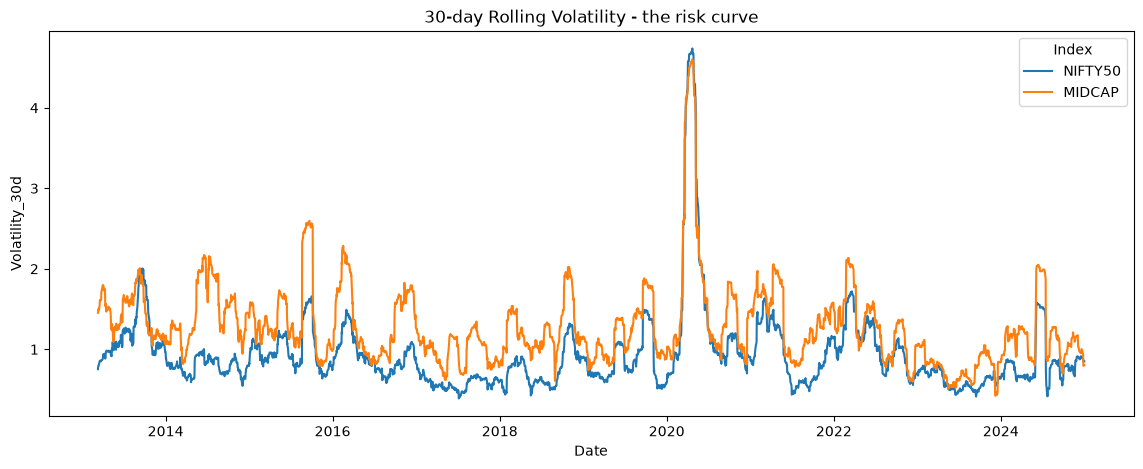

          mean    std     min    max
Index                               
MIDCAP   0.075  1.372 -14.894  6.753
NIFTY50  0.052  1.037 -12.980  8.763
Worst day: 2020-03-20 MIDCAP -14.89 %


In [5]:
# Risk = how wildly returns swing -> 30-day rolling standard deviation
df["Volatility_30d"] = df.groupby("Index")["Daily_Return_%"].transform(lambda x: x.rolling(30).std())

plt.figure(figsize=(14, 5))
sns.lineplot(data=df, x="Date", y="Volatility_30d", hue="Index")
plt.title("30-day Rolling Volatility - the risk curve")
plt.show()

print(df.groupby("Index")["Daily_Return_%"].describe()[["mean", "std", "min", "max"]].round(3))
worst = df.loc[df["Daily_Return_%"].idxmin()]
print("Worst day:", worst["Date"].date(), worst["Index"], round(worst["Daily_Return_%"], 2), "%")

### Objective 3: Does volume predict the move?

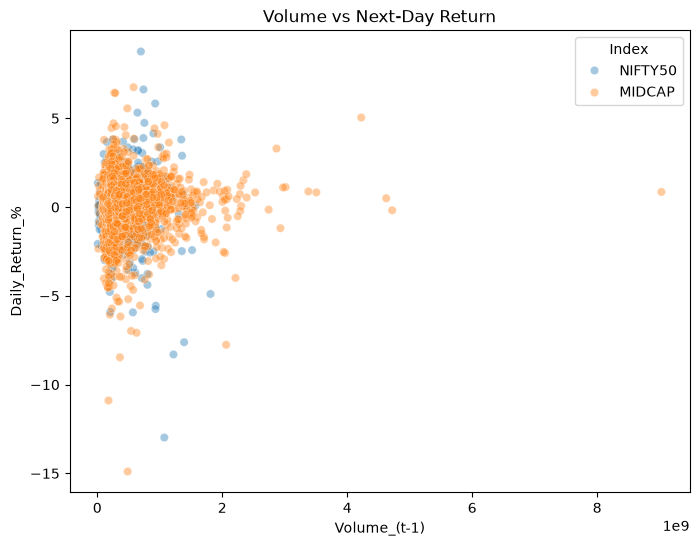

MIDCAP correlation: 0.0519
NIFTY50 correlation: -0.0047


In [6]:
# Objective 3 - yesterday's volume vs today's return
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="Volume_(t-1)", y="Daily_Return_%", hue="Index", alpha=0.4)
plt.title("Volume vs Next-Day Return")
plt.show()

for name, d in df.groupby("Index"):
    print(name, "correlation:", round(d["Volume_(t-1)"].corr(d["Daily_Return_%"]), 4))

### Objective 3: up-days Vs down-days

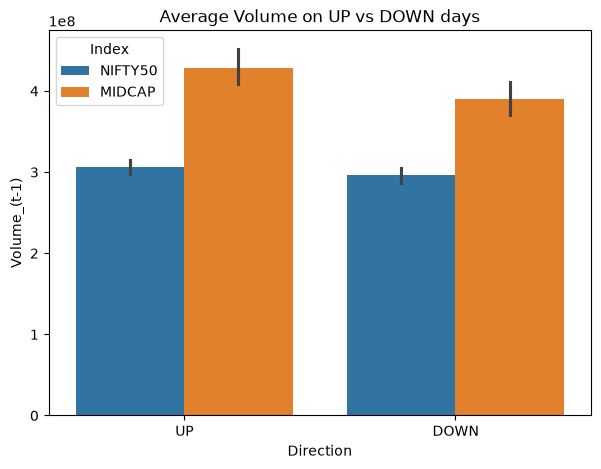

Index    Direction
MIDCAP   UP           57.9
         DOWN         42.1
NIFTY50  UP           54.3
         DOWN         45.7
Name: proportion, dtype: float64


In [7]:
# Do up-days and down-days differ in volume?
df["Direction"] = "UP"
df.loc[df["Daily_Return_%"] < 0, "Direction"] = "DOWN"

plt.figure(figsize=(7, 5))
sns.barplot(data=df, x="Direction", y="Volume_(t-1)", hue="Index")
plt.title("Average Volume on UP vs DOWN days")
plt.show()

print(df.groupby("Index")["Direction"].value_counts(normalize=True).round(3) * 100)

### Objective 4: Which indicators matter

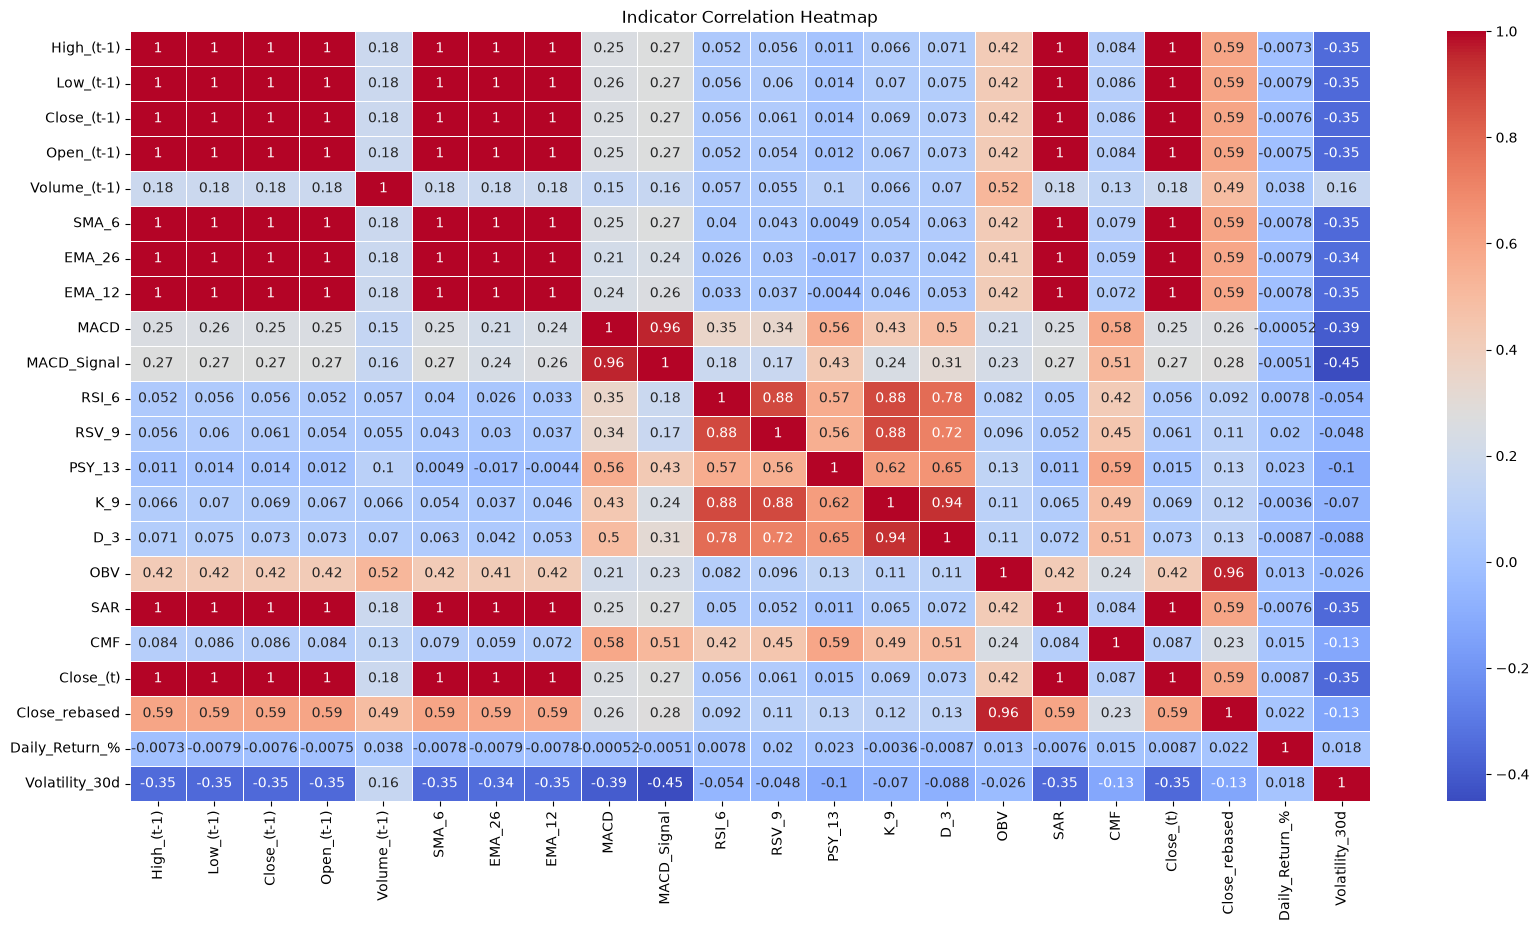

Correlation with Close_(t), strongest first:
Close_(t-1)       1.000
High_(t-1)        1.000
Low_(t-1)         1.000
Open_(t-1)        1.000
SAR               1.000
SMA_6             1.000
EMA_12            0.999
EMA_26            0.999
OBV               0.418
Volatility_30d    0.350
MACD_Signal       0.272
MACD              0.254
Volume_(t-1)      0.182
CMF               0.087
D_3               0.073
K_9               0.069
RSV_9             0.061
RSI_6             0.056
PSY_13            0.015
Daily_Return_%    0.009
Name: Close_(t), dtype: float64


In [10]:
# Objective 4 - correlation of every indicator with the closing price
plt.figure(figsize=(20, 10))
corr = df.corr(numeric_only=True)          # numeric_only: ignore Date/Index/Direction
sns.heatmap(corr, cmap="coolwarm",linewidths=0.5,annot = True)         
plt.title("Indicator Correlation Heatmap")
plt.show()

print("Correlation with Close_(t), strongest first:")
print(corr["Close_(t)"].drop(["Close_(t)", "Close_rebased"]).abs().sort_values(ascending=False).round(3))

## Conclusion of EDA

1. **Objective 1 (Trend):** MIDCAP created (approx) 6.9x wealth vs NIFTY50's (approx) 3.9x (2013-2024) — mid-caps won on growth.
2. **Objective 2 (Risk):** MIDCAP is (approx) 32% riskier daily (volatility 1.37% vs 1.04%), worst day = 20-Mar-2020 COVID crash (-14.9%).
3. **Objective 3 (Volume):** Correlation of volume with next-day return is 0 — heavy volume alone does NOT predict the move.
4. **Objective 4 (Indicators):** SMA/EMA/SAR track the price level (corr ~1.0); RSI/Stochastic track momentum only (corr ~0.0X) — best tested on direction.
5. **Bonus finding:** the market closes UP (approx) 54-58% of days — our baseline for UP/DOWN models.
6. **Data quality:** BANKNIFTY file failed validation (High < Low in 97% rows) and was excluded.